# Precision, recall and the ROC curve

This notebook goes with [AI Visual](https://mohammad-qt.github.io/ML_DL_Vis/learn/10-selection/metrics/). Run the cells in order. We’ll fit one model and move the cutoff without retraining.

## 1. Fit on imbalanced data
Generate overlapping groups with about one positive in ten. Keep a separate, stratified test set so both sets have roughly the same class balance.

In [1]:
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0,
                           weights=[0.9, 0.1], class_sep=0.8, random_state=27)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=9)
model = LogisticRegression().fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]

## 2. Compare two thresholds
The matrix has actual labels on rows and predicted labels on columns, with negative first. Try lowering the threshold below 0.25. What happens to missed positives and false alarms?

In [2]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)

threshold = 0.25
for cutoff in [0.5, threshold]:
    predicted = scores >= cutoff
    print(f'Cutoff: {cutoff:.2f}')
    print(confusion_matrix(y_test, predicted, labels=[0, 1]))
    print(f'Accuracy {accuracy_score(y_test, predicted):.2f}',
          f'Precision {precision_score(y_test, predicted, zero_division=0):.2f}',
          f'Recall {recall_score(y_test, predicted):.2f}',
          f'F1 {f1_score(y_test, predicted):.2f}')
print(f'AUC (all cutoffs): {roc_auc_score(y_test, scores):.3f}')

Cutoff: 0.50
[[268   2]
 [  9  21]]
Accuracy 0.96 Precision 0.91 Recall 0.70 F1 0.79
Cutoff: 0.25
[[264   6]
 [  6  24]]
Accuracy 0.96 Precision 0.80 Recall 0.80 F1 0.80
AUC (all cutoffs): 0.939


## See it
Move `threshold` in the previous cell and rerun both cells. The dots move, but the curves stay put. The dashed line in the precision–recall plot is the share of positives in the test set: the precision you get if you call everything positive.

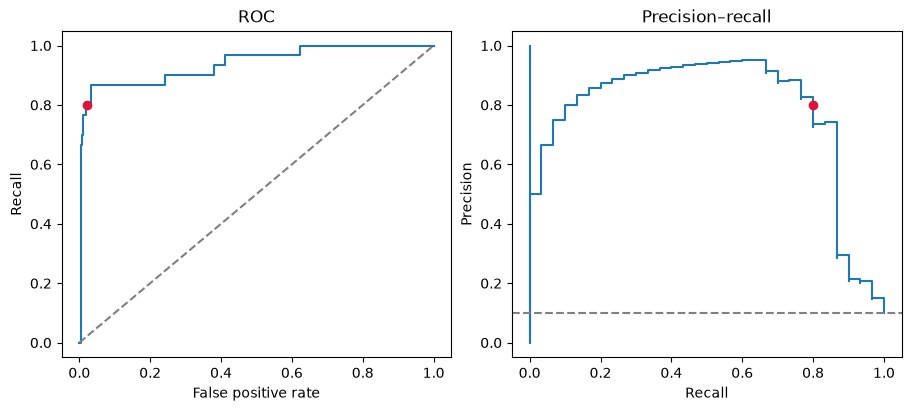

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

fpr, tpr, _ = roc_curve(y_test, scores)
precision, recall, _ = precision_recall_curve(y_test, scores)
chosen = scores >= threshold
tn, fp, fn, tp = confusion_matrix(y_test, chosen, labels=[0, 1]).ravel()
hit_rate = tp / (tp + fn)
false_alarm_rate = fp / (fp + tn)
chosen_precision = precision_score(y_test, chosen, zero_division=0)

fig, (roc_ax, pr_ax) = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
roc_ax.plot(fpr, tpr)
roc_ax.plot([0, 1], [0, 1], '--', color='grey')
roc_ax.scatter(false_alarm_rate, hit_rate, color='crimson', zorder=3)
roc_ax.set(title='ROC', xlabel='False positive rate', ylabel='Recall')
pr_ax.step(recall, precision, where='post')
pr_ax.axhline(y_test.mean(), linestyle='--', color='grey')
pr_ax.scatter(hit_rate, chosen_precision, color='crimson', zorder=3)
pr_ax.set(title='Precision–recall', xlabel='Recall', ylabel='Precision')
plt.show()